# QPDK vortex neck test chip — four λ/4 resonators shorted through narrow necks (Quantcore PDK rebuild)

**What the chip is.** gdsfactory **quantum-rf-pdk** (QPDK) `qpdk/samples/vortex_neck_test_chip.pic.yml`, with the
cells `qpdk/cells/vortex.py` (`neck_termination`) and `qpdk/cells/resonator.py` (`resonator_coupled`),
<https://github.com/gdsfactory/quantum-rf-pdk> — **MIT licence** (gdsfactory 2024; depth-1 clone read 2026-11-03,
never executed). Spec: `docs/designs/qpdk/vortex_neck_test_chip.md`. The geometry follows Shulga *et al.* (2026,
single-vortex observation): the neck sits at the current antinode, so one trapped vortex shifts the resonance.

One straight feedline with four hanger resonators alternating below and above it. Each resonator is **open at its
coupled end**; its far end runs into a `neck_termination`: the centre conductor tapers over 100 µm from 10 µm to a
2 µm, 325 µm-long neck that joins the ground plane at the far edge of a 380 µm-wide etched window. Lengths are
4000 µm + 600 / −300 / +300 / 0 µm.

This notebook **rebuilds** that chip with our components, routes, netlist and LOM on the Quantcore PDK — not a
replica. We distribute the rebuild under GPL-3.0.

| topic | QPDK source | this rebuild (Quantcore PDK) |
|---|---|---|
| die | 4.8 × 5.6 mm chip area, launchers on its edge | the 7.5 × 7.5 mm Quantcore die (`QP.die_box(4800, 5600)`, centred on the source's chip area, so every source coordinate is kept + (100, 2800) µm), Quantcore die frame, device ID "QPDK-VNT" |
| pads | QPDK `launcher` on the chip area's west and east edges | the same `BondPad`s moved to **100 µm** from the die edge (`frame.pad_edge`, `edge="auto"`): 1250 µm out each, so the feedline is 2.5 mm longer |
| substrate | Al on Si (εr 11.45) | Nb on sapphire 650 µm, εr 10.25: the frequencies are not QPDK's |
| junctions | none | none |
| cheese | none (the vortex-trap holes are part of each neck window; no fill) | the PDK band (chip `cheese` `"auto"`), at least 4 µm clear of 3/0; the trap holes stay in the cell |
| elements, positions | — | kept: the necks at the source's placement, the coupled sections at the source's x, the resonator lengths |
| placement | the source's chip area | centred (checked below, no shift) |

**Reproduced:**
- The neck and coupled-section positions (Designer = source + (100, 2800) µm). The coupled sections are 200 µm long
  with a 20 µm gap edge to edge (→ an 8 µm ground strip), at source x 1006 / 1706 / 2606 / 3306 µm, open at the
  west end; they are pinned by position (`near=`), so they stay put when the pads move.
- **The necks:** `NeckTermination` (Quantcore re-implementation of QPDK `neck_termination`, MIT) with the QPDK
  defaults: 10 → 2 µm linear taper over 100 µm, 2 × 325 µm neck shorted at the far edge of a 380 × 425 µm etched
  window, 4 rows of 4 µm vortex-trap holes (pitch 5.5 µm, 6 µm from the window, a 24 µm hole-free column on the
  neck axis). Port `o1` at the source's neck placement (source x, ∓2200 µm), rotation ∓90° as in the YAML.
- **The lead lengths, computed from the QPDK cells (QPDK was not run):** `resonator(length=L, meanders=6)` with the
  `cpw` bend radius 100 µm has 6 half-turns (100π µm each) and 7 equal straights, so `resonator_o2` sits 1200 µm
  beyond `resonator_o1` and (L − 600π)/7 µm east of it, facing east. Every neck is 150.06 µm further east and
  970 µm further out, so each `route_bundle_cpw` lead is one 90° `bend_circular`:
  150.06 + 970 − 2·100 + 50π = **1077.1 µm**. Each route is therefore L + 1077.1 µm, from `N.o1` to the open end
  (the neck adds its own 425 µm).

**Substituted / estimated:**
- The meander shape: the router's KQC `Meander` between the neck and the coupled section, instead of QPDK's 6-turn
  meander hanging from the coupled section plus an L-shaped lead. The length is the same (printed below).
- The neck's LOM is the `NeckTermination` model: the taper + neck as a series line at its inductive-equivalent
  length (ℓ·L′/L′_cpw; the 425 µm drawn ≈ 1279 µm of 10/6 µm CPW), shorted at the window edge. This is a **rough,
  geometric-only estimate**: it has no kinetic inductance, which for a 2 µm Nb neck (and QPDK's Al) adds more.

The notebook walks through the build step by step: setup and the PDK → die and frame → pads → components →
routes → DRC → netlist → LOM simulation → FEM jobs → results back → one design change → fab export →
snapshots → summary.

## 1 · Setup

`LIVE` follows `QCC_LIVE` (default on: KLayout opens and redraws after every change; `QCC_LIVE=0` for batch
runs). `RUN_FEM = False` keeps the FEM step at "export only"; `True` solves the jobs in a new batch AEDT
2024 R1 (if installed). `FULL_FAB = False` skips the fab-only corner rounding in the fab step (`qcc mask` writes the full file).

In [2]:
%config InlineBackend.figure_formats = ["png"]
import math, os, sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
os.chdir(ROOT)                                   # paths below are relative to the repo root
sys.path.insert(0, str(ROOT / "examples" / "designs"))
from _common import *                            # tables, snapshots, PDK and FEM step helpers
from quantcore_circuits.designer import Designer
sys.path.insert(0, str(ROOT / "examples" / "designs" / "qpdk"))
import _qpdk as QP                               # QPDK cell defaults, die box

LIVE = os.environ.get("QCC_LIVE", "1") == "1"   # live KLayout by default; QCC_LIVE=0 for batch runs
RUN_FEM = False                                  # True: solve the exported jobs in a new batch AEDT 2024 R1
FULL_FAB = False                                 # True: also round the corners in the fab export (slow here)
OUT = Path("examples/designs/qpdk")                           # design JSON + final snapshots
STEPS = Path("build/snapshots/vortex_neck_test_chip")  # step-by-step snapshots (build/ is not kept in the repo)

## 2 · The PDK this chip uses

Every rule below comes from the PDK object (`get_pdk()`), not from this notebook: the stack feeds the LOM
estimates and the FEM exports, the frame and pad rule shape the die, the junction rule sizes the junctions,
and the cheese, 3/0 keep-out and corner-rounding rules apply when the mask is written.

This chip has no junctions; it uses the stack (resonator frequencies), the frame and pad rule and the
cheese / 3/0 rules.

In [3]:
display(Markdown(pdk_facts_md()))

| PDK rule | value |
|---|---|
| process | `quantcore_nb_sapphire_v1` v3 |
| stack | sapphire 650 µm, εr 10.25, Nb film (λ_L 0.09 µm) |
| CPW default | centre 10 µm, gap 6 µm, bend radius 100 µm |
| die frame | standard die 7.5 × 7.5 mm; L dicing markers (1000/0, 25 µm wide), 3 × 3 alignment grids (1001/0) in 500 µm corner areas, boundary 100/0, device ID |
| pad rule | bond pads / launchers: outer etch edge **100 µm** (`frame.pad_edge`) from the die edge (`edge="auto"`) |
| junctions | Nb/AlOx/Nb trilayer, Nb Δ 1.4 meV, R_n 40–50 kΩ (nominal 45 kΩ = 0.5 × 0.6 µm), C_J 50 fF/µm²; fingers 2/0 + 4/0, spacer 50/0 (+ 51–53/0 dose gradient) |
| qubit band | f_q 4–8 GHz (outside: DRC design warning `pdk_fq`) |
| cheese | the original design's own if it has one, else the PDK band: 5 µm squares, 20 µm gaps, 3 rows around the 3/0 keep-outs (chip param `cheese`: auto / pdk / original) |
| 3/0 keep-out | filled second-metal etch: routes CPW footprint + 10 µm, components etch bbox + 24 µm (or the cell's own) |
| corner rounding | fab only: r = 0.25 × the shortest dimension, ≤ 10 µm |

## 3 · The die and its frame

`Designer(...)` starts the chip on the 7.5 × 7.5 mm Quantcore die. `QP.die_box(4800, 5600)` centres the source's
4.8 × 5.6 mm chip area in it, so the source's coordinates are kept: a source point (x, y) sits at
(x + `DX`, y + `DY`) = (x + 100, y + 2800) µm. The chip name "QPDK-VNT" is the device ID. The frame is the PDK
default (L dicing markers 1000/0, 3 × 3 alignment grids 1001/0, boundary 100/0), and the chip `cheese` stays
`"auto"`: the source has no fill, so the build draws the PDK band.

die box: (-1350.0, -950.0, 6150.0, 6550.0)


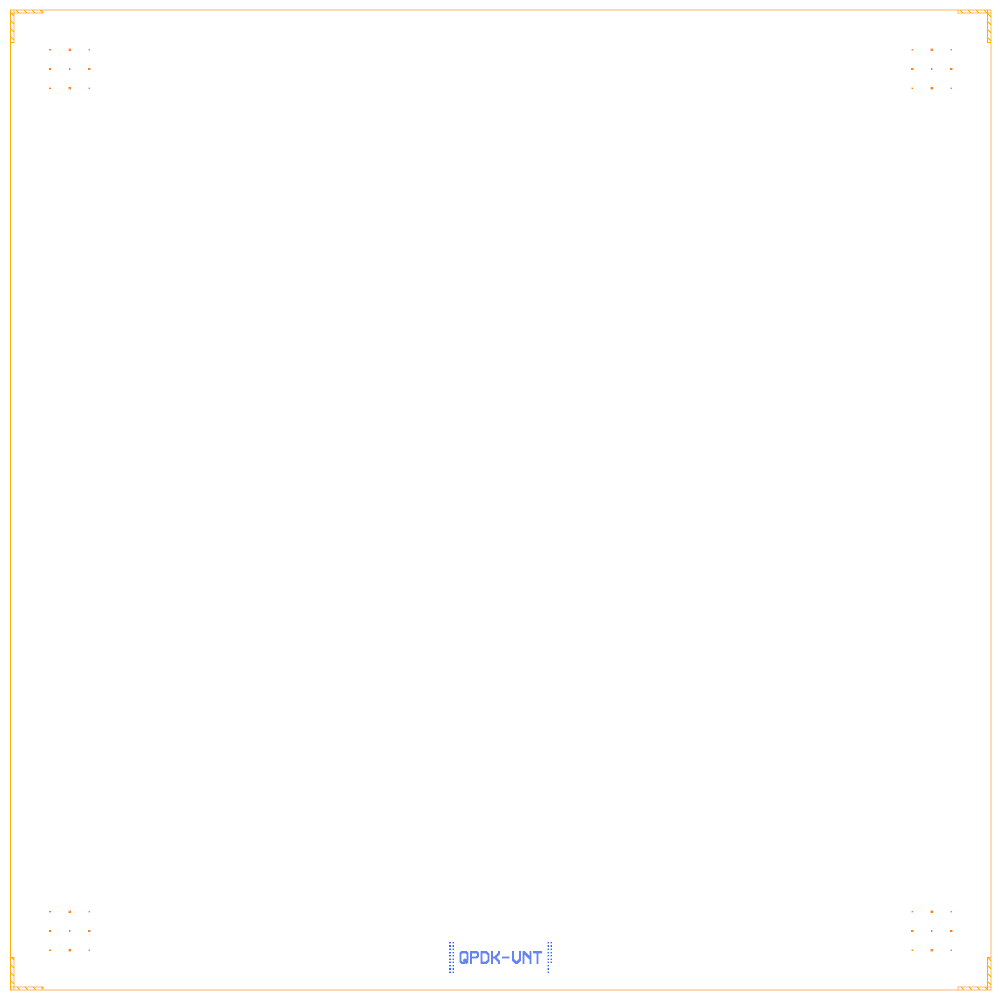

In [4]:
W, H = 4800, 5600                                # the source's chip area (µm)
DX, DY = 100, 2800                               # Designer = QPDK source + (DX, DY)
d = Designer("vortex_neck_test_chip", box=QP.die_box(W, H), chip={"name_chip": "QPDK-VNT"}, live=LIVE)
print("die box:", d.design.chip.box)
snap(d, STEPS / "1_die.png", size=(1000, 1000), width=400);

## 4 · Pads and the pad rule

QPDK's `launcher` is a KQC-style `BondPad` here (`QP.LAUNCHER`: 200 × 200 µm pad, 110 µm gap, 100 µm taper).
**PDK rule:** the outer etch edge of a pad sits `frame.pad_edge` (100 µm) from the die edge. `edge="auto"` in
`d.add` applies it: the pad keeps its position along the nearest die edge (here the feedline's y) and slides
perpendicular to it until its etch ends 100 µm from it. In the source the pads sit on the 4.8 mm chip area's
edge, 1350 µm inside our die edges; the rule moves each 1250 µm out. The table measures the result.

| pad | cell / launcher | nearest die edge | outer etch → die edge (µm) | PDK rule |
|---|---|---|---|---|
| PW | `BondPad` | w | 100.0 | ✓ |
| PE | `BondPad` | e | 100.0 | ✓ |

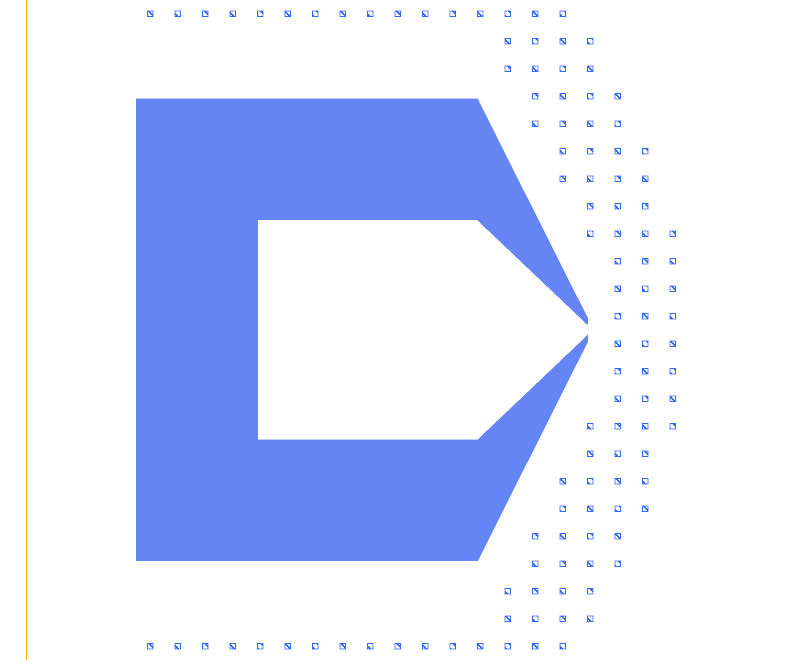

In [5]:
with d.batch():
    pw = d.add("PW", "BondPad", at=(QP.LAUNCHER_DEPTH, DY), rot=270, edge="auto", **QP.LAUNCHER)
    pe = d.add("PE", "BondPad", at=(W - QP.LAUNCHER_DEPTH, DY), rot=90, edge="auto", **QP.LAUNCHER)
rebuild(d)                                       # a live=False Designer builds on request: the table reads this build
display(Markdown(pads_md(d)))
x0, _, _, _ = d.design.chip.box
snap(d, STEPS / "2_pad.png", box=(x0 - 20, DY - 300, x0 + 700, DY + 300), size=(800, 660), width=360);

## 5 · Components

The four `NeckTermination`s at the source's neck placement: port `o1` at (source x, ∓2200 µm), facing the
feedline (rotation ∓90°), with the QPDK defaults (taper, 2 µm × 325 µm neck, 380 × 425 µm window, vortex-trap
holes). They are named after the resonator's length step: `p600` = 4000 + 600 µm, `m300` = 4000 − 300 µm, …

{'p600': (1643.919, 600.0, 90.00000000000001), 'm300': (2215.347, 5000.0, -90.00000000000001)}


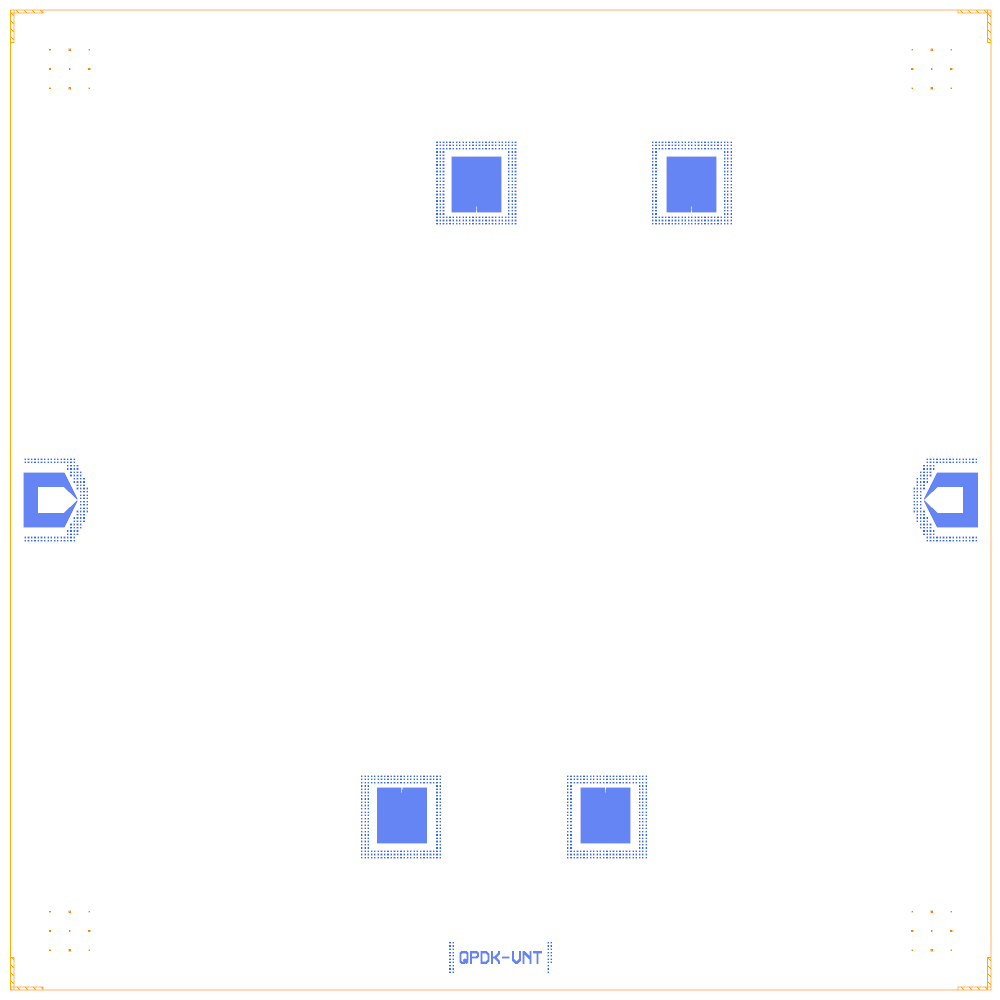

In [6]:
# name, length, coupled-section start (source x), neck x (source), below (-1) / above (+1) the feedline
RES = (("p600", 4600, 1006, 1543.919, -1), ("m300", 3700, 1706, 2115.347, +1),
       ("p300", 4300, 2606, 3101.061, -1), ("0", 4000, 3306, 3758.204, +1))
with d.batch():
    for name, L, x_cpl, x_neck, sgn in RES:
        d.add(f"N_{name}", "NeckTermination", at=(DX + x_neck, DY + sgn * 2200), rot=90 * sgn)
print({n: port_info(d, f"N_{n}.o1") for n in ("p600", "m300")})   # (x, y, direction °): o1 faces the feedline
snap(d, STEPS / "3_components.png", size=(1000, 1000), width=400);

## 6 · Routes

**The feedline** `FL` runs straight from PW to PE (CPW 10/6 µm, r = 100 µm).

**The resonators.** Each runs from its neck's `o1`, 400 µm towards the feedline, east along a jog to the coupled
section's east end, and into a 200 µm hanger coupler on the feedline: `fl.hanger(near=(x, y), length=200,
ground_gap=8, end="open", direction="backward")` centres the coupler at the feedline point nearest (x, y) — the
source's coupled-section centre — with an 8 µm ground strip and the open end to the west. `meander=L + LEAD`
fits a 6-turn meander of the full length (L plus the QPDK lead computed above).

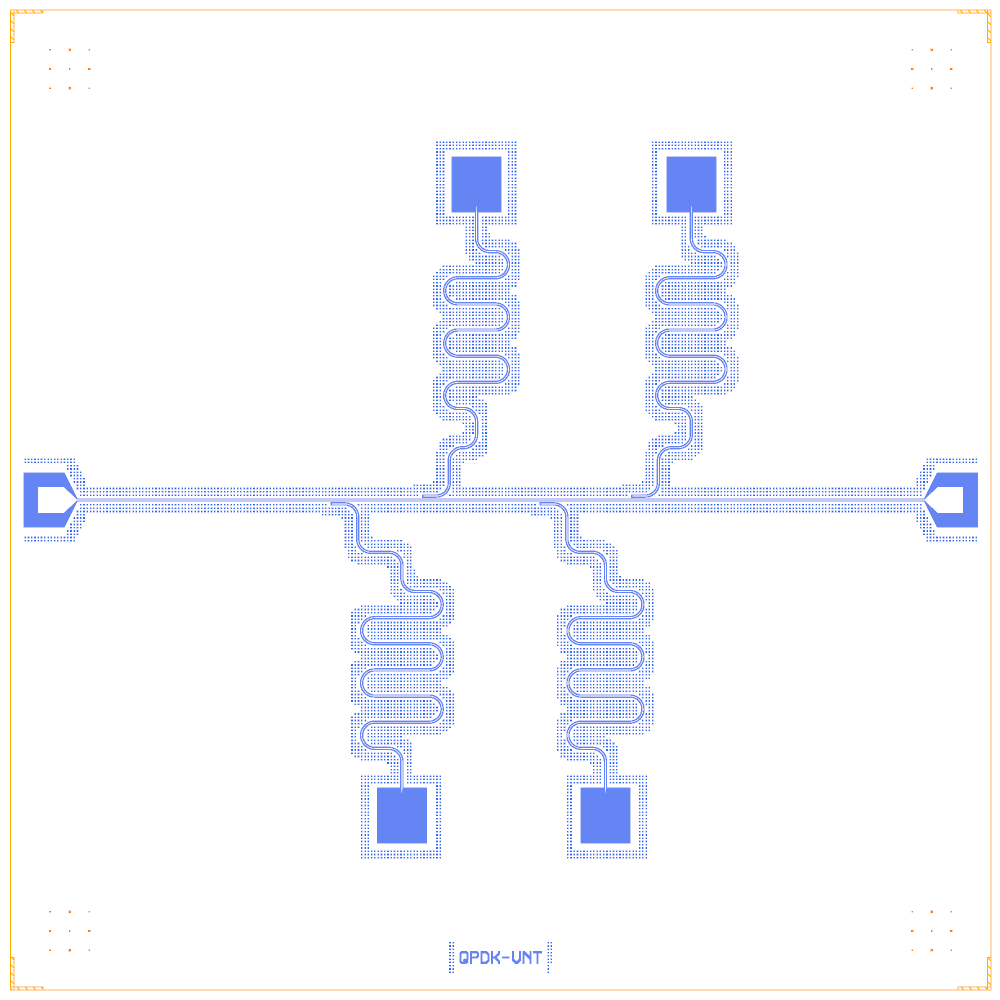

lead 1077.1 µm; {'FL': 6480.0, 'R_p600': 5677.1, 'R_m300': 4777.1, 'R_p300': 5377.1, 'R_0': 5077.1}


In [7]:
R_BEND = 100.0                                   # QPDK cpw bend radius
LEAD = 150.06 + 970 - 2 * R_BEND + math.pi * R_BEND / 2   # QPDK lead resonator_o2 → neck o1 (computed above): 1077.1 µm
with d.batch():
    fl = d.route("FL", pw.a, pe.a, r=QP.CPW_R)
    for name, L, x_cpl, x_neck, sgn in RES:
        xn, yn = DX + x_neck, DY + sgn * 2200
        x_east = DX + x_cpl + 200                     # east end of the coupled section (the route arrives here)
        y_jog = DY + sgn * 400
        d.route(f"R_{name}", f"N_{name}.o1",
                fl.hanger(near=(x_east - 100, DY), length=200, side="left" if sgn > 0 else "right",
                          ground_gap=8, direction="backward", end="open"),
                meander=L + LEAD, r=QP.CPW_R, nodes=[(xn, y_jog), (x_east, y_jog)]).set(meanders=6)
snap(d, STEPS / "4_routes.png", size=(1000, 1000), width=400)
print(f"lead {LEAD:.1f} µm;", {k: round(v, 1) for k, v in d.result.route_lengths().items()})

**Sim group, centring, save.** One sim group: the feedline with its four resonators and necks (eigenmode, 200 µm
margin; the feedline ends in the pads' 50 Ω ports, so each mode's Q gives κ). `center_in_die` checks that the
content sits centred in the die and shifts it if it is more than 50 µm off — here it is centred (the pads and the
alternating resonators are symmetric about the die centre), so nothing moves. Then the design is saved.

In [8]:
ALL = ["FL"] + [f"{p}_{n}" for n in ("p600", "m300", "p300", "0") for p in ("R", "N")]
d.sim_group("ALL", ALL, margin_um=200, analyses=["eigenmode_epr"])
print("centring shift (µm):", center_in_die(d))
rebuild(d)
DESIGN = d.save(OUT / "vortex_neck_test_chip.json")
print(d, "→", DESIGN)

centring shift (µm): (0.0, 0.0)
<Designer vortex_neck_test_chip: 6 instances, 5 routes, live=False> → examples\designs\qpdk\vortex_neck_test_chip.json


## 7 · DRC

The DRC reports three kinds of issue. **Errors** (overlaps, crossings without a bridge, unconnected ends, metal
outside the die) make the build unfit for fab. **Warnings** are connectivity or geometry notes to read. **PDK
design warnings** flag values outside the PDK margins (`pad_edge`, `pdk_rn`, `pdk_fq`, `pdk_claw`): flagged,
never enforced — the rebuild keeps the source's choices. `pdk_report` adds the cheese source, the centring
and the junction types.

**Here:** DRC clean: no errors, no warnings and no PDK design warnings (both pads at 100 µm, no junctions). `pdk_report` gives the PDK band drawn in the build, the content centred (0, 0) and no junctions.

In [9]:
display(Markdown(drc_md(d.drc())))
display(Markdown(pdk_report(d)))

**0 errors · 0 warnings · 0 PDK design warnings** (DRC clean)

| kind | rule | count | first message |
|---|---|---|---|

| check | value |
|---|---|
| cheese | PDK band (drawn in the build) |
| content centre − die centre | (+0, +0) µm |
| junction types | — |
| PDK design warnings | 0 (none) |

## 8 · Netlist and LOM

`d.lom()` turns the layout into a lumped circuit: the feedline is one node between the two 50 Ω pad ports; each
resonator route is a λ/4 `TLres`, open at the hanger end and shorted through its neck (the `NeckTermination` model
adds the taper + neck as a series line at its inductive-equivalent length); the hanger coupling is the coupled-line
capacitance to the feedline.

In [10]:
lb = d.lom()
show_netlist(lb)

**6 nodes · 10 branches · 0 controls · 0 unconnected ports**

| node | FEM nets |
|---|---|
| `gnd` | ground |
| `FL` | `FL`, `PW.pad`, `PE.pad` |
| `N_p600.line` | `N_p600.line` |
| `N_m300.line` | `N_m300.line` |
| `N_p300.line` | `N_p300.line` |
| `N_0.line` | `N_0.line` |

| branch | type | nodes | estimate |
|---|---|---|---|
| `Port_PW` | R | `FL` – `gnd` | 50 Ω |
| `Port_PE` | R | `FL` – `gnd` | 50 Ω |
| `R_p600` | TLres | `N_p600.line` – `gnd` | lambda/4, 6956 µm, 4.530 GHz |
| `K_R_p600` | HANGER | `N_p600.line` – `FL` | κ 0.0173 MHz (L 200 µm) |
| `R_m300` | TLres | `N_m300.line` – `gnd` | lambda/4, 6056 µm, 5.203 GHz |
| `K_R_m300` | HANGER | `N_m300.line` – `FL` | κ 0.0262 MHz (L 200 µm) |
| `R_p300` | TLres | `N_p300.line` – `gnd` | lambda/4, 6656 µm, 4.734 GHz |
| `K_R_p300` | HANGER | `N_p300.line` – `FL` | κ 0.0198 MHz (L 200 µm) |
| `R_0` | TLres | `N_0.line` – `gnd` | lambda/4, 6356 µm, 4.957 GHz |
| `K_R_0` | HANGER | `N_0.line` – `FL` | κ 0.0227 MHz (L 200 µm) |

**Unconnected ports:** none

**Builder notes:**

- N_p600: taper 100 µm + neck 325 µm counted as 1279 µm of 10/6 µm CPW (L' ratio 3.14 for the neck; rough: no neck L_k beyond the CPW formula, no C of the window)
- N_m300: taper 100 µm + neck 325 µm counted as 1279 µm of 10/6 µm CPW (L' ratio 3.14 for the neck; rough: no neck L_k beyond the CPW formula, no C of the window)
- N_p300: taper 100 µm + neck 325 µm counted as 1279 µm of 10/6 µm CPW (L' ratio 3.14 for the neck; rough: no neck L_k beyond the CPW formula, no C of the window)
- N_0: taper 100 µm + neck 325 µm counted as 1279 µm of 10/6 µm CPW (L' ratio 3.14 for the neck; rough: no neck L_k beyond the CPW formula, no C of the window)
- R_p600: one lambda/4 line of 6956 µm through ['N_p600'] and route(s) ['R_p600']; pass-through section(s) ['N_p600'] enter by (equivalent) length only, the width step is not modelled (one Z0, a/b 10/6 µm)
- R_m300: one lambda/4 line of 6056 µm through ['N_m300'] and route(s) ['R_m300']; pass-through section(s) ['N_m300'] enter by (equivalent) length only, the width step is not modelled (one Z0, a/b 10/6 µm)
- R_p300: one lambda/4 line of 6656 µm through ['N_p300'] and route(s) ['R_p300']; pass-through section(s) ['N_p300'] enter by (equivalent) length only, the width step is not modelled (one Z0, a/b 10/6 µm)
- R_0: one lambda/4 line of 6356 µm through ['N_0'] and route(s) ['R_0']; pass-through section(s) ['N_0'] enter by (equivalent) length only, the width step is not modelled (one Z0, a/b 10/6 µm)

## 9 · LOM simulation

The feedline with its four resonators: four linear modes (no junctions, so no anharmonicity), their frequencies
and κ into the two 50 Ω pads. The source states no targets. The 0.3 / 0.6 mm length steps keep the four modes
apart. The neck model is geometric only, so the real necks (kinetic inductance) sit lower in frequency.

In [11]:
res = simulate_groups(d, {"ALL": ALL}, max_modes=4)
display(Markdown(modes_md(res["ALL"])))

| mode | kind | f (GHz) | κ (MHz) | A (MHz) | participation |
|---|---|---|---|---|---|
| R_p600 | resonator | 4.5223 | 0.0172 | 0.0 | R_p600 1.00 |
| R_p300 | resonator | 4.7258 | 0.0196 | 0.0 | R_p300 1.00 |
| R_0 | resonator | 4.9485 | 0.0225 | 0.0 | R_0 1.00 |
| R_m300 | resonator | 5.1931 | 0.026 | 0.0 | R_m300 1.00 |

**Here:** four resonator modes at 4.522 (R_p600), 4.726 (R_p300), 4.949 (R_0) and 5.193 GHz (R_m300), each on its own line (participation 1.00), with κ 0.017–0.026 MHz into the pads (Q_ext ≈ 2.0–2.6 × 10⁵). The LOM counts each neck as 1279 µm of 10/6 µm CPW (the builder notes in step 8), so the four λ/4 lines are 6056–6956 µm long.

## 10 · FEM: send the jobs

One job per sim group and analysis: the group is cut out of the chip with its margin, every line leaving the
box ends in a port, junctions are lumped ports, and the ground grid is removed (simulation exports never have
cheese). The table lists each job's ports and C-matrix nets (named after islands, couplers and routes, so the
result maps back onto the LOM nodes).

With `RUN_FEM = True` and AEDT 2024 R1 (or later) installed, `send_fem_jobs` solves each Ansys job in a **new
batch, non-graphical** AEDT (`solve_job`) — an AEDT window you have open is never touched. The command-line
equivalent is `qcc sim run build/jobs/<job>` (or `qcc sim submit` to the Linux server).

Here: one eigenmode job for the feedline with its four resonators (the feedline ends in its pads' 50 Ω
ports, so each mode's Q gives κ). In a C-matrix the shorted λ/4 is part of ground, so there is no Q3D job.

In [12]:
jobs = send_fem_jobs(DESIGN, analyses=["eigenmode_epr"], run=RUN_FEM)
display(Markdown(jobs_md(jobs) if jobs else "No sim groups: no FEM job."))

1 job(s) exported; RUN_FEM is False, nothing solved.


| group | job | ports (number · kind · name) | C-matrix nets |
|---|---|---|---|
| ALL · eigenmode_epr | `build/jobs/vortex_neck_test_chip_ALL_eigenmode_epr` | 1 · lumped · `PE.pad`<br>2 · lumped · `PW.pad` | `PE.pad` |

## 11 · Bring the results back

When a job has been solved its folder holds `results/results.json`. `fem_back` then calls
`fill(model, design, job)`: the C-matrix (or eigenmode) values replace the component estimates branch by
branch (matched by net name), and the table compares the two. `simulate(filled)` re-runs the LOM on the
extracted values. Until then the cell says which jobs are still waiting.

In [13]:
filled, md = fem_back(lb.model, DESIGN, jobs)
display(Markdown(md or "No FEM jobs."))
if filled:
    from quantcore_circuits.lom.simulate import simulate
    key, fc = next(iter(filled.items()))
    display(Markdown(f"**LOM on the FEM values ({key}):**\n\n" + modes_md(simulate(fc, max_modes=2))))

No FEM results yet for ALL · eigenmode_epr: after a solve, `results/results.json` appears in each job folder and this cell shows the C-matrix (or eigenmode) values next to the LOM estimates; `simulate(filled)` then re-runs the LOM on the extracted values.

## 12 · Change one property and re-simulate

The neck is this chip's subject: its inductance sets how far the shorted end sits electrically beyond the drawn
line. Widen R_0's neck from 2 to 6 µm: the neck's inductive-equivalent length shrinks, so R_0's λ/4 gets shorter and
its frequency rises; the other three resonators do not change. The change is made on a copy (`design_copy`), so
`vortex_neck_test_chip.json` keeps QPDK's 2 µm.

In [14]:
d2 = design_copy(DESIGN)
d2["N_0"].set(neck_width=6)
after = simulate_groups(d2, {"ALL": ALL}, max_modes=4)
m0, m1 = {m.label: m for m in res["ALL"].modes}, {m.label: m for m in after["ALL"].modes}
display(Markdown("**N_0 neck width: 2 → 6 µm**\n\n| mode | f before (GHz) | f after (GHz) | Δf (MHz) | κ before (MHz) | κ after (MHz) |\n"
                 "|---|---|---|---|---|---|\n" + "\n".join(
                     f"| {k} | {m0[k].f_GHz:.4f} | {m1[k].f_GHz:.4f} | {1e3 * (m1[k].f_GHz - m0[k].f_GHz):+.1f} | "
                     f"{m0[k].kappa_MHz:.3g} | {m1[k].kappa_MHz:.3g} |" for k in m0 if k in m1)))

**N_0 neck width: 2 → 6 µm**

| mode | f before (GHz) | f after (GHz) | Δf (MHz) | κ before (MHz) | κ after (MHz) |
|---|---|---|---|---|---|
| R_p600 | 4.5223 | 4.5223 | -0.0 | 0.0172 | 0.0172 |
| R_p300 | 4.7258 | 4.7258 | -0.0 | 0.0196 | 0.0196 |
| R_0 | 4.9485 | 5.1081 | +159.7 | 0.0225 | 0.0248 |
| R_m300 | 5.1931 | 5.1931 | -0.0 | 0.026 | 0.026 |

**Result.** R_0 moves from 4.9485 to 5.1081 GHz (+160 MHz) and its κ from 0.0225 to 0.0248 MHz; the other three modes do not move. The wider neck is a shorter inductive-equivalent line, so R_0's λ/4 is electrically shorter.

## 13 · Build and export

**The design file.** `vortex_neck_test_chip.json` (saved in step 6) is the whole design: `qcc build
examples/designs/qpdk/vortex_neck_test_chip.json` rebuilds `build/vortex_neck_test_chip.oas` + its sidecar, and the KLayout plugin,
`qcc watch` and the dashboard read it.

**The fab mask.** `export_fab` writes only the PDK fab layers: base etch 1/0 (with the cheese), the filled 3/0 keep-out (CPW footprint + 10 µm, components' etch bbox + 24 µm; 3/0 also holds every cheese
hole), no junction layers (there are none),
and the frame (100/0, 1000/0, 1001/0). The cheese source is `build`: the PDK band drawn in the build (the source has no fill), 5 µm holes in
3 rows round the 3/0 keep-outs and at least 4 µm from them; the necks' own vortex-trap holes are part
of the cell's etch. In this run: 1/0 11 424 polygons (the etch with the necks' trap holes and the band's holes), 3/0 7735 (the keep-outs plus the band's holes); cheese source `build`, 7731 holes. Corner rounding (fab only) is skipped unless `FULL_FAB`;
`qcc mask examples/designs/qpdk/vortex_neck_test_chip.json` writes the complete file.

In [15]:
display(Markdown(fab_layers_md(d, cheese=True, rounding=FULL_FAB)))

| fab layer | PDK name | polygons |
|---|---|---|
| 1/0 | M1 | 11424 |
| 3/0 | M3 | 7735 |
| 100/0 | CHIP_BOUNDARY | 1 |
| 1000/0 | MARKERS_DICING | 4 |
| 1001/0 | MARKERS_ALIGN | 36 |

**Cheese:** source `build`, 7731 holes on the mask.

→ `build/vortex_neck_test_chip_fab.oas`

**Simulation export options.** A simulation export never has cheese; airbridges are dropped for speed unless
`airbridges=True` (or the sim group's `settings={"airbridges": True}`), and the builder notes which crossing
lines are then open. `setup.geometry` says what the export left out. This chip has no airbridges, so both settings give the same geometry.

In [16]:
from quantcore_circuits.sim_tools import build_simulation
for ab in (False, True):
    setup = build_simulation(DESIGN, "ALL", "eigenmode_epr", airbridges=ab)
    print(f"airbridges={ab}:", setup.geometry, *setup.notes)

airbridges=False: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'dropped', 'bends_simplified_um': 0.05} bends simplified by at most 0.05 µm in the simulation (a polygon had more than 4000 points, the GDS XY record limit); the fab layout is unchanged


airbridges=True: {'ground_grid_shapes': 0, 'airbridge_shapes': 0, 'airbridges': 'kept', 'bends_simplified_um': 0.05} bends simplified by at most 0.05 µm in the simulation (a polygon had more than 4000 points, the GDS XY record limit); the fab layout is unchanged


## 14 · Snapshots

The full chip (the pads at the die edges, the four resonators alternating below and above the feedline, the PDK
cheese band round the CPWs); the neck of R_p600 (taper, 2 µm neck, window and trap holes); its open coupled end
on the feedline; the die frame's south-west corner (dicing L on 1000/0, 3 × 3 alignment grid on 1001/0); and the
R_p600 neck in the **fab view** (the mask from step 13: 1/0 with the trap holes and the band, 3/0). The chip
boundary 100/0 is drawn as an outline.

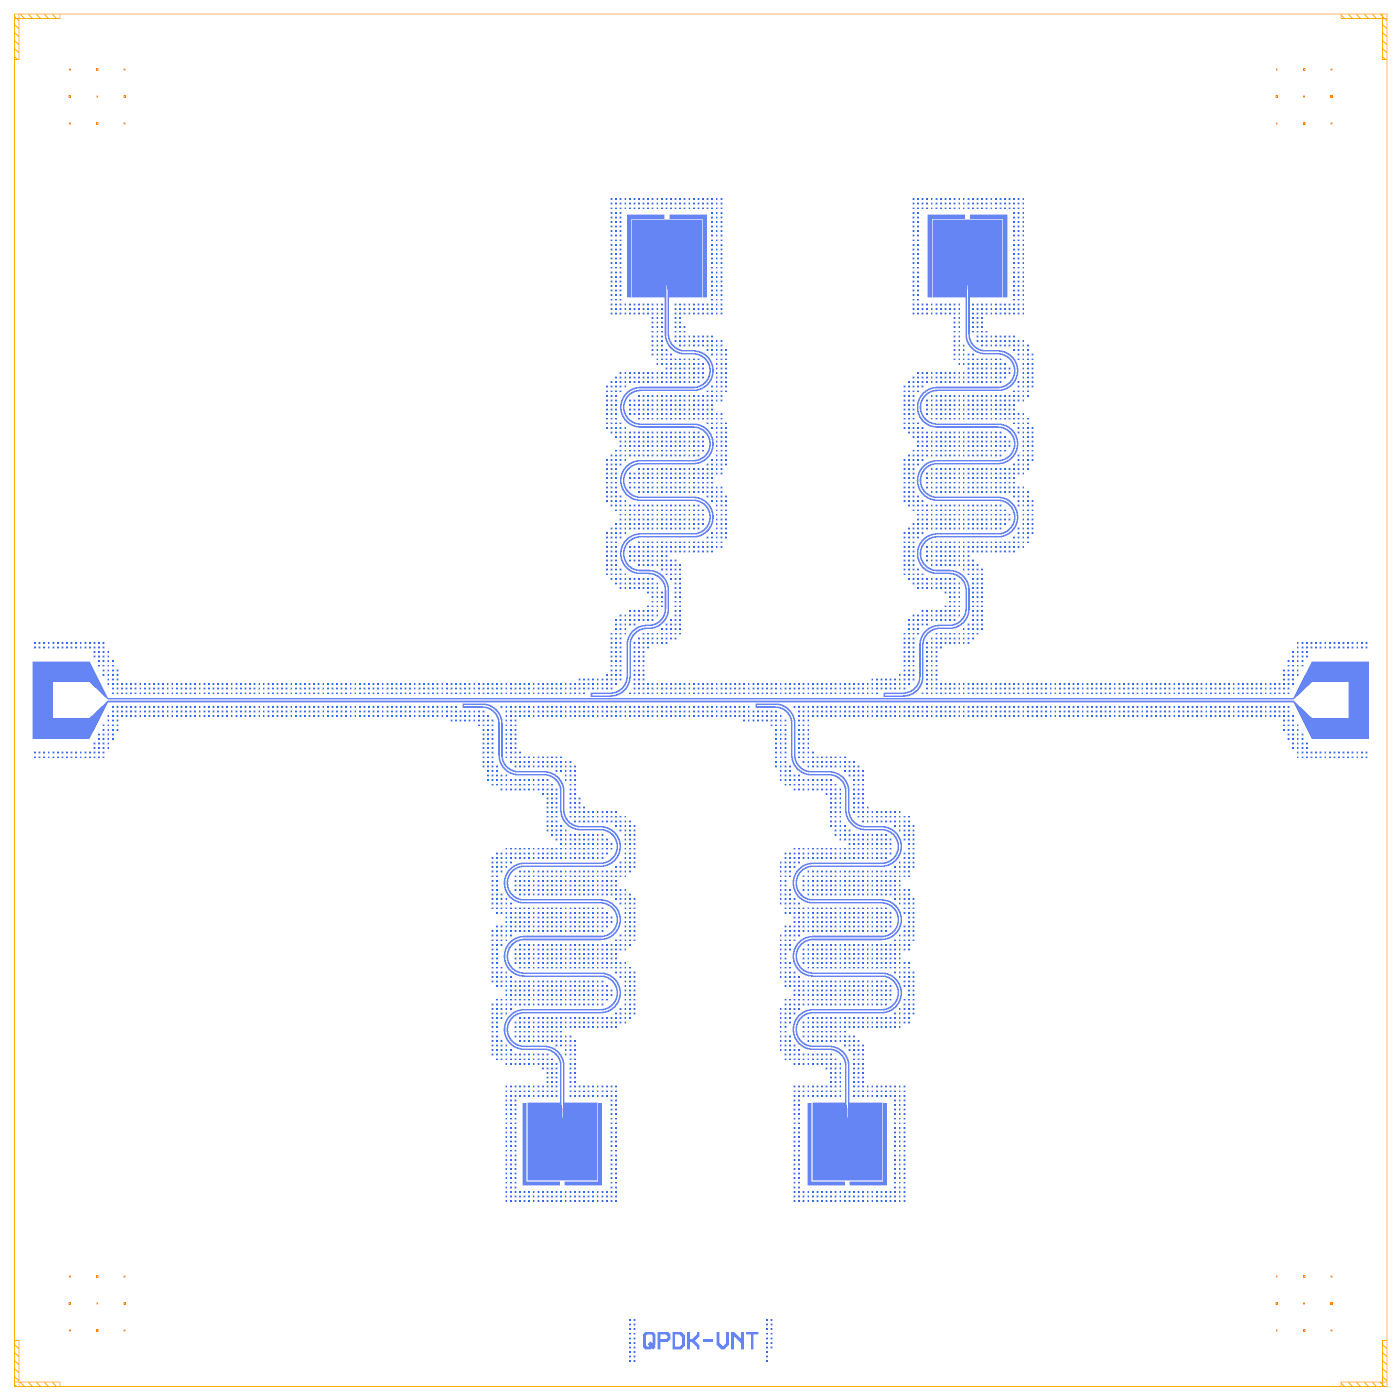

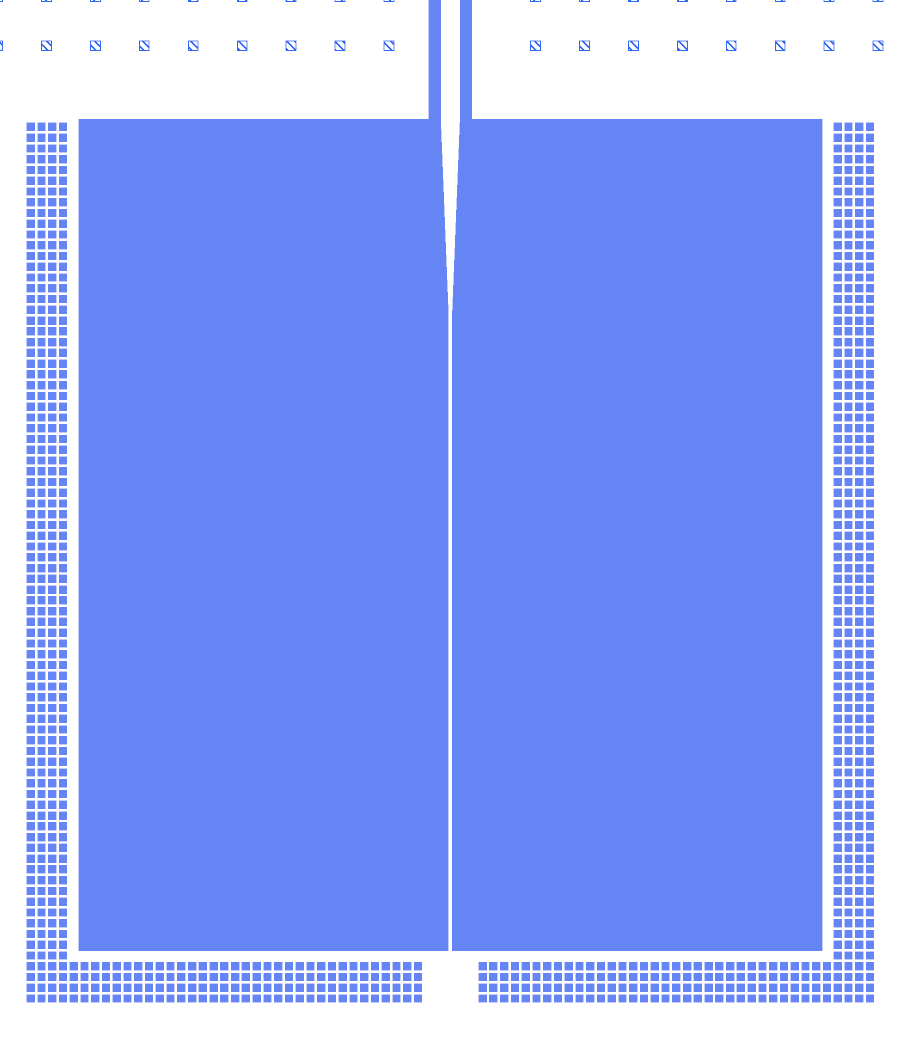

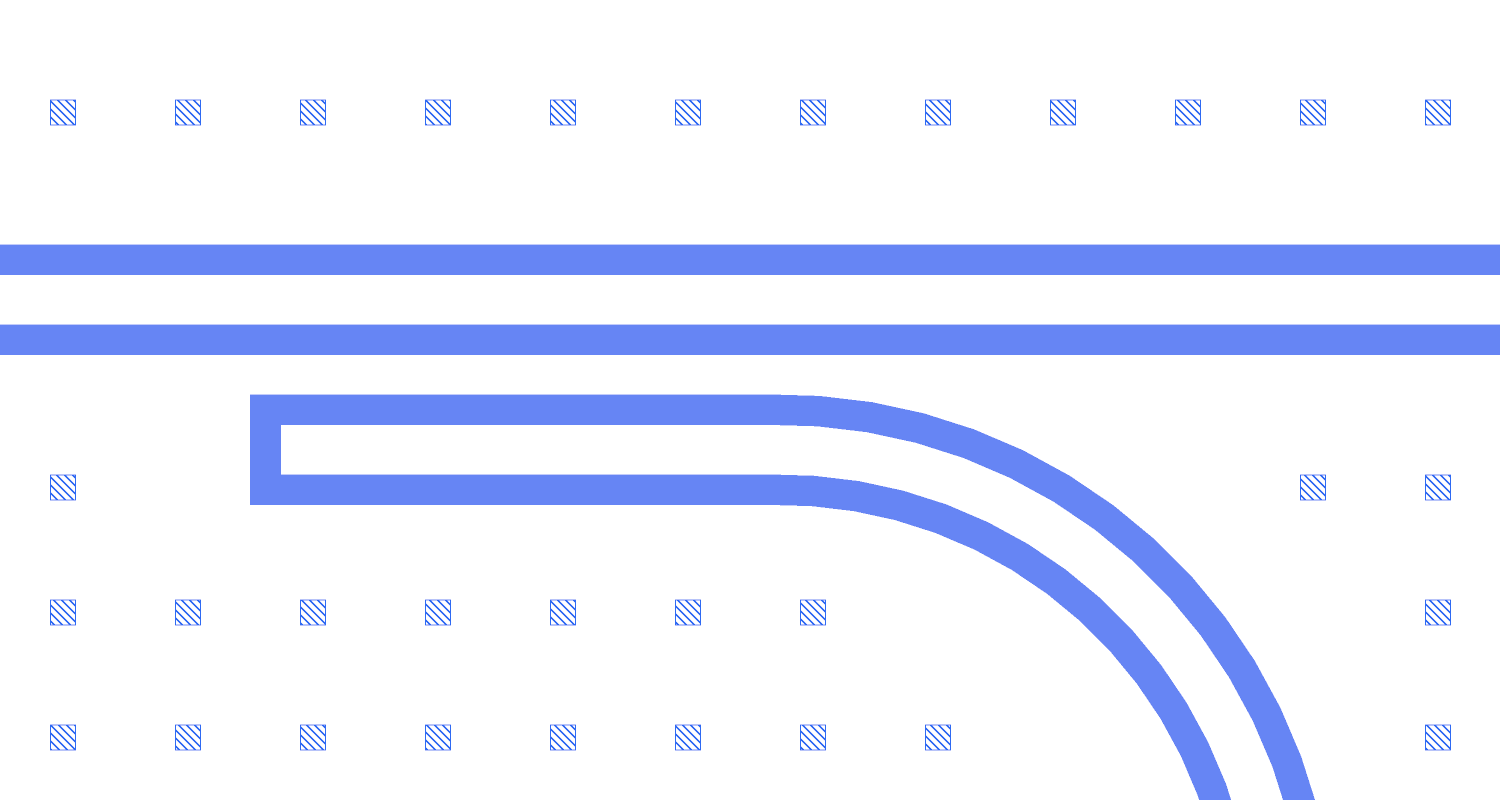

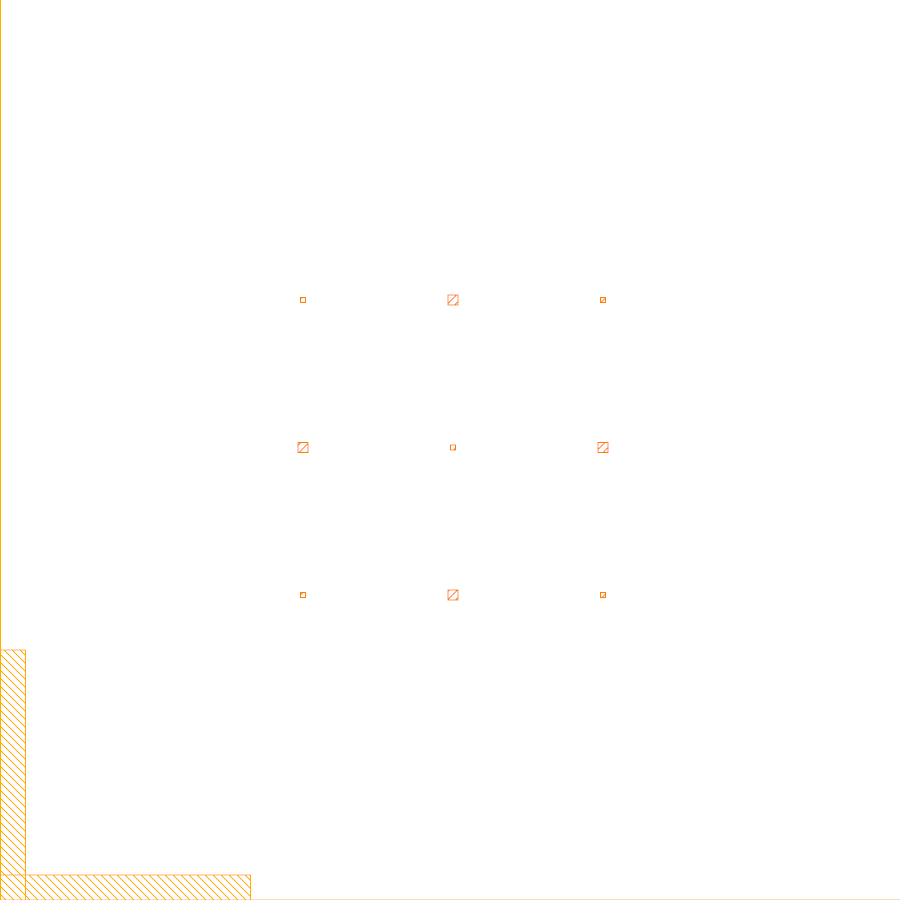

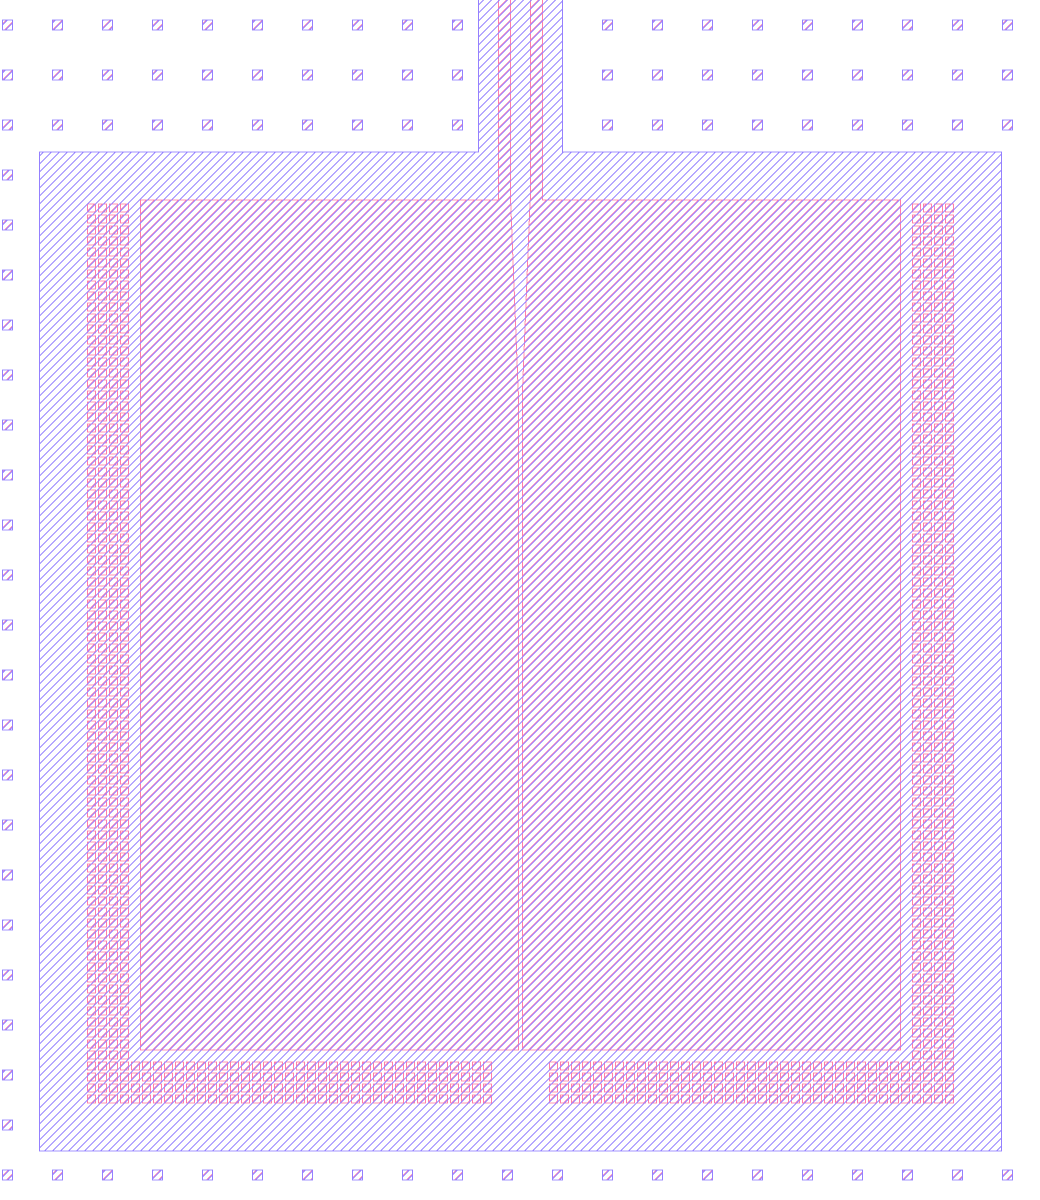

In [17]:
show_snapshot(d, OUT / "vortex_neck_test_chip.png", size=(1400, 1400), width=560)
xn, yn = DX + 1543.919, DY - 2200
show_snapshot(d, OUT / "vortex_neck_test_chip_short.png", box=(xn - 230, yn - 470, xn + 230, yn + 60), size=(900, 1040),
              width=420)
show_snapshot(d, OUT / "vortex_neck_test_chip_coupler.png", box=(1050, 2700, 1350, 2860), size=(1500, 800), width=480)
show_snapshot(d, OUT / "vortex_neck_test_chip_frame.png", box=(-1350, -950, -450, -50), size=(900, 900), width=300)
snap_file(Path("build") / "vortex_neck_test_chip_fab.oas", OUT / "vortex_neck_test_chip_fab_neck.png",
          box=(xn - 260, yn - 500, xn + 260, yn + 100), size=(1040, 1200), width=420);

## 15 · Summary

| | |
|---|---|
| **matches the source** | the netlist (feedline, four open-ended hangers, four neck shorts); the neck geometry (QPDK defaults); the neck and coupled-section positions; the resonator lengths (L + the computed 1077.1 µm lead) |
| **differs (PDK)** | the 7.5 mm Quantcore die with its frame; the pads 100 µm from the die edge (1250 µm out each), so the feedline is 2.5 mm longer; sapphire and Nb instead of Al on Si; the PDK cheese band |
| **estimated** | the neck's LOM (geometric inductance only, no kinetic inductance); the meander shape |
| **PDK design warnings** | none (DRC clean) |
| **FEM** | 1 eigenmode job exported (`build/jobs/vortex_neck_test_chip_ALL_eigenmode_epr`), not solved here |